id: notebooks/05_correlator.ipynb

FX correlator on the simulated SDR signals: fractional delay, fringe stopping, delay/rate search, cross spectra, visibilities

<!-- notebooks/05_correlator.ipynb -- FX correlator (Interferosim 0.6.0) -->
# 05 – The FX correlator

---
  DI Erich Schubert, 07925151
  


A VLB interferometer records the IQ streams of its stations independently (notebook 00); the correlator combines them afterwards. The example is a test of the VLB chain on a short baseline: two 3 m dishes 15 m apart, **each with its own B210**, observing the Sun – strong enough that every step is visible in single channels and seconds. This notebook builds the **FX correlator** step by step on simulated streams (notebook 03) whose stations have instrument errors the correlator does not know – a clock offset (missing or inaccurate time synchronisation) and an LO frequency offset (independent frequency references) – and shows how the correlator finds and removes them.

Package: `interferosim.signal` – `FXCorrelator`, and the correlation kernels taken over from AAS6 `modules/interfero/correlate.py`: `fractional_delay`, `fringe_stop`, `Accumulator`/`cross_spectrum`, `delay_rate_search`, `apply_fringe_solution`, `stokes_from_products`.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.instrument import Antenna, Receiver, Site, Station, Array
from interferosim.sky import SkyModel
from interferosim.sky import FieldCenter
from interferosim.signal import (IQSimulator, StationErrors, FXCorrelator, cross_spectrum,
                                 apply_fringe_solution)
from interferosim.observation import sun_radec_deg, mjd_from_iso

CFG = Path("..") / "configs"
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
dish = Antenna.from_toml(CFG / "antennas" / "dish_3m.toml")
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
cyga = SkyModel.from_json(CFG / "skies" / "cyg_a.json")
ra_sun, dec_sun = (float(x) for x in sun_radec_deg(mjd_from_iso("2026-11-01T11:00:00")))
sun = SkyModel.from_json(CFG / "skies" / "sun_21cm.json")
sun.center = FieldCenter("Sun", ra_sun, dec_sun)
SOURCES = {"sun": sun, "cyg_a": cyga}

def ew_array(b_m):
    return Array(site, [Station.from_enu("A", site, 0, 0, 0, dish),
                        Station.from_enu("B", site, b_m, 0, 0, dish)], receiver=b210, name=f"east-west {b_m:g} m")

FS = 1.0e5                        # sample rate of the notebook
CLOCK_B = 37.3e-6                 # clock offset of station B [s] (no common time reference)
LO_B = 0.8                        # LO offset of station B [Hz] (independent GPSDO)
sim = IQSimulator(sun, ew_array(15.0), sample_rate_sps=FS, seed=4,
                  errors={"B": StationErrors(lo_offset_hz=LO_B, clock_offset_s=CLOCK_B)})
blocks = sim.simulate(12.0)
V_MODEL = sim.expected_visibility(0, 1, *sim.uvw(6.0)[0, :2])
print(f"Sun, two 3 m dishes 15 m east-west, {FS / 1e3:g} kS/s, 12 s;  station B: clock offset {CLOCK_B * 1e6:.1f} µs "
      f"= {CLOCK_B * FS:.2f} samples, LO offset {LO_B} Hz")
print(f"model visibility {V_MODEL:.0f} Jy  (|V| = {abs(V_MODEL):.0f} Jy)")

Sun, two 3 m dishes 15 m east-west, 100 kS/s, 12 s;  station B: clock offset 37.3 µs = 3.73 samples, LO offset 0.8 Hz
model visibility 227055+0j Jy  (|V| = 227055 Jy)


## 1. The principle

| Step | Operation | Purpose |
|---|---|---|
| model correction | shift station $j$ by the geometric delay $\tau_g(t)$ of the phase centre, multiply by $e^{+2\pi i f_c\tau_g(t)}$ | delay tracking and fringe stopping with the geometry (notebook 03) |
| **F** | cut each stream into windows of $N_\mathrm{FFT}$ samples, window function, FFT | spectrum $X_k(f)$ per window, $N_\mathrm{FFT}$ channels of width $f_s/N_\mathrm{FFT}$ |
| **X** | $X_i(f)\,X_j^*(f)$, averaged over the integration time | cross spectrum = visibility per channel |
| fringe solution | search residual delay and residual rate on a bright segment, remove them | clock and LO offsets of the stations |

A residual delay $\Delta\tau$ shows up as a **phase slope across the band**, $\Delta\varphi(f) = -2\pi f\,\Delta\tau$; a residual rate $\Delta f$ as a **phase drift in time**, $2\pi\,\Delta f\,t$. Both make the channel-averaged visibility collapse. (The XF alternative – cross-correlate first, Fourier transform the lags afterwards – gives the same result; FX is cheaper for many channels and is what the AAS6 correlator does.)

## 2. Cross spectrum with the geometric model only

The model removes the geometry, but not the unknown clock and LO offsets of station B. Left: the phase of the cross spectrum over the band for the first three integrations – a straight slope (clock offset) that moves from integration to integration (LO offset). Right: the **lag spectrum** (inverse FFT of the cross spectrum): the correlation peak sits at the residual delay instead of at zero.

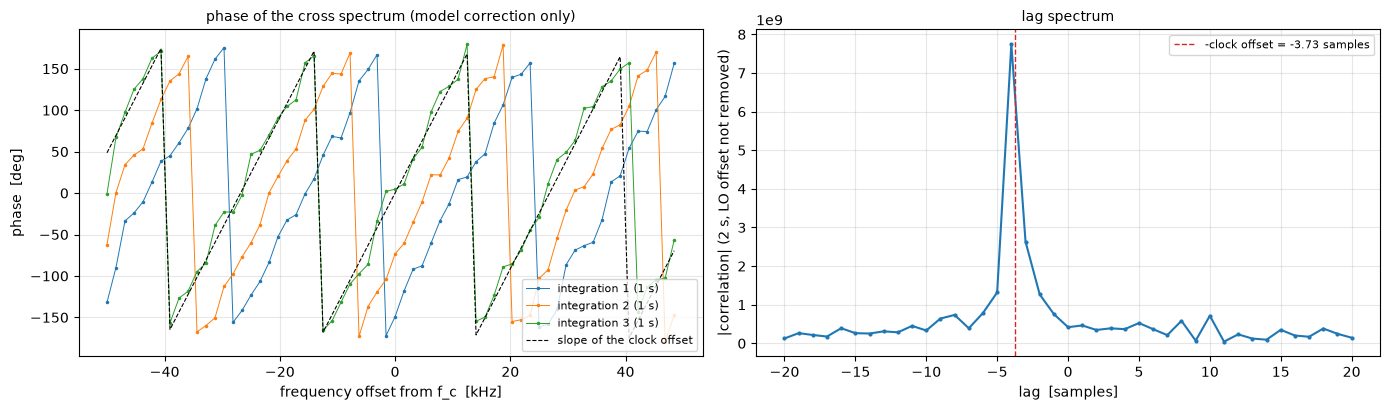

channel-averaged visibility per second [Jy]: [ 3194.+2578.j -3778.+6914.j -3984. +297.j   527. -328.j  4745.+2157.j
   880.+4256.j]


In [2]:
fx = FXCorrelator(nfft=64, t_int_s=1.0)
v_model_only = fx.correlate(blocks, sim)
f_khz = (v_model_only.freq_hz - sim.fc) / 1e3
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for r in range(3):
    axes[0].plot(f_khz, np.degrees(np.angle(v_model_only.vis[r])), ".-", ms=3, lw=0.7, label=f"integration {r + 1} (1 s)")
axes[0].plot(f_khz, np.degrees(np.angle(np.exp(-2j * np.pi * f_khz * 1e3 * (-CLOCK_B)))), "k--", lw=0.8,
             label="slope of the clock offset")
axes[0].set_xlabel("frequency offset from f_c  [kHz]"); axes[0].set_ylabel("phase  [deg]")
axes[0].set_title("phase of the cross spectrum (model correction only)", fontsize=10); axes[0].legend(fontsize=8)
streams = fx.correct(blocks, sim)
n = int(2 * FS)
xps = np.fft.fft(streams["A"][:n]) * np.conj(np.fft.fft(streams["B"][:n]))
lag = np.fft.fftshift(np.fft.fftfreq(n, 1 / n)); corr = np.abs(np.fft.fftshift(np.fft.ifft(xps)))
sel = np.abs(lag) <= 20
axes[1].plot(lag[sel], corr[sel], ".-", ms=4)
axes[1].axvline(-CLOCK_B * FS, color="C3", ls="--", lw=1, label=f"-clock offset = {-CLOCK_B * FS:.2f} samples")
axes[1].set_xlabel("lag  [samples]"); axes[1].set_ylabel("|correlation| (2 s, LO offset not removed)")
axes[1].set_title("lag spectrum", fontsize=10); axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()
avg = v_model_only.average_channels()
print("channel-averaged visibility per second [Jy]:", np.round(avg.vis[:6, 0], 0))

The LO offset of 0.8 Hz turns the phase by almost a full turn per second: the lag peak of a 2-s segment is smeared and the channel average of each integration is reduced and rotated instead of showing the model visibility.

## 3. Delay–rate search

`delay_rate_search` (AAS6) fringe-stops station B with a grid of trial rates and, for each, finds the delay as the peak of the lag spectrum: a 2-D search surface over (delay, rate). Its maximum is the **fringe solution**. The quadratic interpolation of the peak leaves a sub-sample bias (up to about 0.3 samples for white noise), so `FXCorrelator.search` refines the solution afterwards (`refine_fringe_solution`): the remaining phase slope across the band gives the delay, the remaining phase drift over sub-segments the rate.

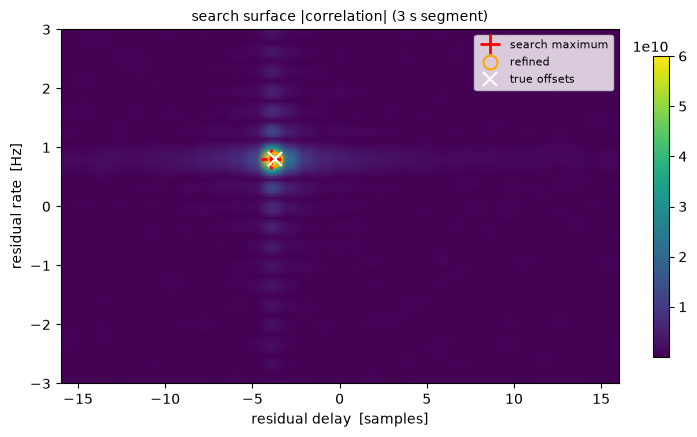

search maximum  delay -3.946 samples = -39.46 µs (true -37.30 µs),  rate +0.8004 Hz (true +0.800 Hz)
refined         delay -3.729 samples = -37.29 µs (true -37.30 µs),  rate +0.8008 Hz (true +0.800 Hz)
SNR of the search peak 183.6


In [3]:
sol0 = fx.search(blocks, sim, "B", segment_s=3.0, max_delay_samples=16, max_rate_hz=3.0, n_rate=121, refine=False)
sol = fx.search(blocks, sim, "B", segment_s=3.0, max_delay_samples=16, max_rate_hz=3.0, n_rate=121)
fig, ax = plt.subplots(figsize=(9, 4.6))
ext = [sol.delay_grid[0] * FS, sol.delay_grid[-1] * FS, sol.rate_grid[0], sol.rate_grid[-1]]
im = ax.imshow(sol.surface, origin="lower", aspect="auto", extent=ext, cmap="viridis")
ax.plot(sol0.delay_samples, sol0.rate_hz, "r+", ms=14, mew=2, label="search maximum")
ax.plot(sol.delay_samples, sol.rate_hz, "o", mfc="none", mec="orange", ms=10, mew=1.5, label="refined")
ax.plot(-CLOCK_B * FS, LO_B, "wx", ms=10, mew=1.5, label="true offsets")
ax.set_xlabel("residual delay  [samples]"); ax.set_ylabel("residual rate  [Hz]")
ax.set_title("search surface |correlation| (3 s segment)", fontsize=10); ax.legend(fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.85); plt.show()
for label, so in (("search maximum", sol0), ("refined", sol)):
    print(f"{label:<15s} delay {so.delay_samples:+.3f} samples = {so.delay_samples / FS * 1e6:+.2f} µs "
          f"(true {-CLOCK_B * 1e6:+.2f} µs),  rate {so.rate_hz:+.4f} Hz (true {LO_B:+.3f} Hz)")
print(f"SNR of the search peak {sol.snr:.1f}")

## 4. Cross spectra after the fringe solution

With the solution applied the phase is flat across the band and stable in time; the amplitude per channel scatters around the model visibility (the source is a continuum source – the same visibility in every channel). The channel average of each integration now agrees with the model within the noise. A constant phase offset may remain (the LO phase of each station is unknown – in a real observation it is calibrated on a calibrator source); a residual rate error from the noise of the search segment lets the phase creep slowly – a longer segment reduces it.

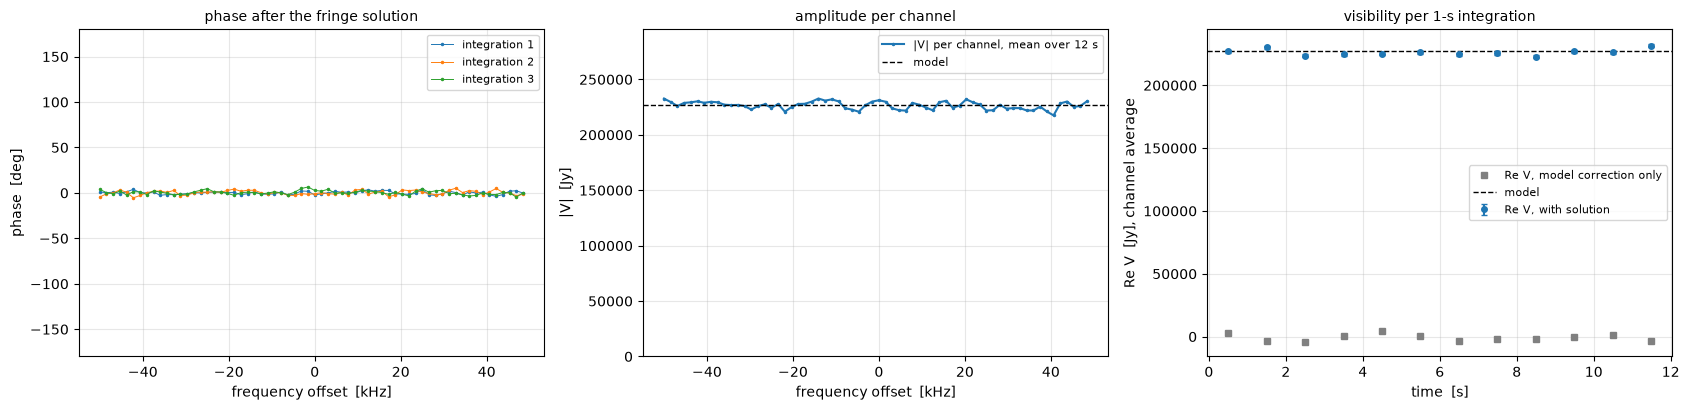

mean over 12 s: 226256+6165j Jy (model 227055+0j Jy), noise 358 Jy


In [4]:
v_fixed = fx.correlate(blocks, sim, solutions={"B": sol})
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for r in range(3):
    axes[0].plot(f_khz, np.degrees(np.angle(v_fixed.vis[r])), ".-", ms=3, lw=0.7, label=f"integration {r + 1}")
axes[0].set_ylim(-180, 180); axes[0].set_title("phase after the fringe solution", fontsize=10)
axes[0].set_xlabel("frequency offset  [kHz]"); axes[0].set_ylabel("phase  [deg]"); axes[0].legend(fontsize=8)
axes[1].plot(f_khz, np.abs(v_fixed.vis.mean(axis=0)), ".-", ms=3, label="|V| per channel, mean over 12 s")
axes[1].axhline(abs(V_MODEL), color="k", ls="--", lw=1, label="model")
axes[1].set_xlabel("frequency offset  [kHz]"); axes[1].set_ylabel("|V|  [Jy]")
axes[1].set_ylim(0, 1.3 * abs(V_MODEL))
axes[1].set_title("amplitude per channel", fontsize=10); axes[1].legend(fontsize=8)
a0, a1 = v_model_only.average_channels(), v_fixed.average_channels()
t = a1.time_mjd * 86400
axes[2].errorbar(t, a1.vis[:, 0].real, yerr=a1.sigma[:, 0], fmt="o", ms=4, capsize=2, label="Re V, with solution")
axes[2].plot(t, a0.vis[:, 0].real, "s", ms=4, color="grey", label="Re V, model correction only")
axes[2].axhline(V_MODEL.real, color="k", ls="--", lw=1, label="model")
axes[2].set_xlabel("time  [s]"); axes[2].set_ylabel("Re V  [Jy], channel average")
axes[2].set_title("visibility per 1-s integration", fontsize=10); axes[2].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()
m = np.average(a1.vis[:, 0], weights=a1.weight[:, 0])
print(f"mean over 12 s: {m:.0f} Jy (model {V_MODEL:.0f} Jy), noise {1 / np.sqrt(a1.weight[:, 0].sum()):.0f} Jy")

## 5. Channels, integration time and noise

Each channel has the width $f_s/N_\mathrm{FFT}$; its noise is $\sqrt{N_\mathrm{FFT}}$ times that of the channel average. More channels resolve spectral lines (HI, OH masers – notebook 09) and reduce the bandwidth smearing of wide fields; a longer integration lowers the noise, but a residual rate or the changing geometry smears the phase within it.

In [5]:
print(f"{'N_FFT':>6s} {'channel width':>14s} {'sigma per channel (1 s)':>24s} {'sigma channel average':>22s}")
for nfft in (16, 64, 256, 1024):
    v = FXCorrelator(nfft=nfft, t_int_s=1.0).correlate(blocks, sim, solutions={"B": sol})
    s_ch = np.median(v.sigma); s_avg = np.median(v.average_channels().sigma)
    print(f"{nfft:6d} {FS / nfft / 1e3:11.3f} kHz {s_ch:21.0f} Jy {s_avg:19.0f} Jy")

 N_FFT  channel width  sigma per channel (1 s)  sigma channel average
    16       6.250 kHz                  4952 Jy                1238 Jy
    64       1.562 kHz                  9921 Jy                1239 Jy
   256       0.391 kHz                 19826 Jy                1237 Jy
  1024       0.098 kHz                 39580 Jy                1229 Jy


## 6. The result: `VisData` with a frequency axis

The correlator writes one row per integration and baseline with `nfft` channels – the same data class as the visibility simulation (notebook 04), so imaging (notebook 06) works on simulated and correlated data alike. The header records the correlator settings.

In [5]:
print(v_fixed.n_rows, "rows x", v_fixed.n_chan, "channels;", f"{v_fixed.freq_hz[0] / 1e6:.4f} ... {v_fixed.freq_hz[-1] / 1e6:.4f} MHz")
print({k: v_fixed.header[k] for k in ("NFFT", "INTTIME", "WINDOW", "MODELCOR", "FRINGSOL", "SIMULATD")})
out = Path("sim_output"); out.mkdir(exist_ok=True)
print(v_fixed.save_npz(out / "sun_15m_fx.npz").name)

12 rows x 64 channels; 1420.3558 ... 1420.4542 MHz
{'NFFT': 64, 'INTTIME': 0.99968, 'WINDOW': 'hann', 'MODELCOR': True, 'FRINGSOL': ['B'], 'SIMULATD': True}
sun_15m_fx.npz


## 7. Selector

Source (Sun or Cygnus A – much weaker, use baselines of 50–300 m), baseline length, clock and LO offset of station B, number of channels and integration time; with or without fringe search. *Run Interact* simulates 10 s at 100 kS/s and correlates. (Needs a running kernel; a run takes several seconds.)

In [6]:
import ipywidgets as widgets
from IPython.display import display

def run_fx(source, baseline_m, clock_us, lo_hz, nfft, t_int_s, search):
    s = IQSimulator(SOURCES[source], ew_array(baseline_m), sample_rate_sps=FS, seed=6,
                    errors={"B": StationErrors(lo_offset_hz=lo_hz, clock_offset_s=clock_us * 1e-6)})
    bl = s.simulate(10.0)
    c = FXCorrelator(nfft=nfft, t_int_s=t_int_s)
    sols = {}
    if search:
        so = c.search(bl, s, "B", segment_s=3.0, max_delay_samples=max(16, 2 * abs(clock_us) * FS * 1e-6),
                      max_rate_hz=max(3.0, 2 * abs(lo_hz)), n_rate=161)
        sols = {"B": so}
        print(f"solution: delay {so.delay_samples / FS * 1e6:+.2f} µs (true {-clock_us:+.2f}), "
              f"rate {so.rate_hz:+.3f} Hz (true {lo_hz:+.3f}), SNR {so.snr:.1f}")
    v = c.correlate(bl, s, solutions=sols)
    exp = s.expected_visibility(0, 1, *s.uvw(5.0)[0, :2])
    fk = (v.freq_hz - s.fc) / 1e3
    a = v.average_channels()
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    axes[0].plot(fk, np.degrees(np.angle(v.vis.mean(axis=0))), ".-", ms=3)
    axes[0].set_xlabel("frequency offset [kHz]"); axes[0].set_ylabel("phase [deg]"); axes[0].set_ylim(-180, 180)
    axes[0].set_title("phase of the mean cross spectrum", fontsize=10)
    axes[1].errorbar(a.time_mjd * 86400, np.abs(a.vis[:, 0]), yerr=a.sigma[:, 0], fmt="o", ms=4, capsize=2)
    axes[1].axhline(abs(exp), color="k", ls="--", lw=1)
    axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("|V| [Jy], channel average"); axes[1].set_title("visibility per integration", fontsize=10)
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.tight_layout(); plt.show()
    print(f"model |V| = {abs(exp):.0f} Jy, measured mean = {abs(np.average(a.vis[:, 0], weights=a.weight[:, 0])):.0f} Jy")

display(widgets.interactive(
    run_fx, {"manual": True},
    source=widgets.Dropdown(options=list(SOURCES), value="sun", description="source"),
    baseline_m=widgets.FloatLogSlider(value=15, base=10, min=0.7, max=3, description="baseline [m]"),
    clock_us=widgets.FloatSlider(value=37.3, min=-150, max=150, step=0.1, description="clock B [µs]"),
    lo_hz=widgets.FloatSlider(value=0.8, min=-3, max=3, step=0.05, description="LO B [Hz]"),
    nfft=widgets.Dropdown(options=[16, 32, 64, 128, 256], value=64, description="N_FFT"),
    t_int_s=widgets.Dropdown(options=[0.25, 0.5, 1.0, 2.0], value=1.0, description="t_int [s]"),
    search=widgets.Checkbox(value=True, description="fringe search"),
))

interactive(children=(Dropdown(description='source', options=('sun', 'cyg_a'), value='sun'), FloatLogSlider(va…